In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:

DATA_FOLDER = Path("data")
BARO_FILES = ["Baro B_261008103222_Y3119.CSV"]


CL = 1.847                 # top of casing down to the Diver sensor, m (same for all wells)
BARO_OFFSET = -0.875 
NEST_DEPTH_CM = 60         # turtle nesting depth below the sand surface, cm
GAP_MINUTES = 5            # a break longer than this is drawn as blank space
COLOURS = ["#0a91a1", "#74c9b9", "#f47c53", "#f8a953"]

TIDE_FILE = "QUINTA_tides_2030.csv"
TIDE_SHIFT_HOURS = -6      # tide file is in UTC, the Divers are in UTC-6
PROFILE_FILE = "well_transect_profile.csv"   # beach elevation profile: distance_m, Monday, Tuesday, Wednesday
B1_DISTANCE_M = 36.7       # where well B1 sits along that profile (m from the start of the profile)

# z             = elevation of the SAND SURFACE at the well (drone survey), m above MSL
# x, y          = GPS coordinates (only needed for the B wells, used for the cross-section)
# above_sand_cm = how far the casing sticks out above the sand, cm
# files         = each Diver file with (keep_from, keep_until); None = no limit
WELLS = {
    "A1": {"z": 3.945, "above_sand_cm": 49.0,"z_is_top_of_casing": True,"offset_cm": -1.657, "files": {
        "A1_261008102201_1358A.CSV": (None, None),
        "A1_261008102313_1358A.CSV": (None, None),
        "A1_261008102323_1358A.CSV": (None, None),
        "A1_261008102348_1358A.CSV": (None, None),
        "A1_261008102401_1358A.CSV": (None, None),
        "A1_261008102412_1358A.CSV": (None, None),
        "A1_261008102422_1358A.CSV": (None, None),
    }},
    "A2": {"z": 4.076, "above_sand_cm": 61.2,"z_is_top_of_casing": True,"offset_cm": 1.602, "files": {
        "B2_261008102819_DF001.CSV": (None, None),
    }},
    "B1": {"z": 2.820, "above_sand_cm": 40.0, "x": 713336.927, "y": 9888748.650,"z_is_top_of_casing": False,"offset_cm": 0.888, "files": {
        "B1_261008102503_AL116.CSV": ("2026-09-28 14:20:00", "2026-09-28 21:54:00"),
        "B1_261008102515_AL116.CSV": (None, None),
        "B1_261008102528_AL116.CSV": (None, None),
        "B1_261008102543_AL116.CSV": (None, "2026-09-30 07:50:22.5"),
        "B1_261008102556_AL116.CSV": (None, None),
        "B1_261008102613_AL116.CSV": (None, None),
        "B1_261008102626_AL116.CSV": (None, "2026-10-01 17:00:41"),
    }},
    "B2": {"z": 2.752, "above_sand_cm": 44.2, "x": 713334.080, "y": 9888757.182,"z_is_top_of_casing": False,"offset_cm": 1.602, "files": {
        "B2_261008102642_DF001.CSV": ("2026-09-28 14:20:00", "2026-09-28 21:55:46"),
        "B2_261008102704_DF001.CSV": ("2026-09-28 22:40", "2026-09-29 08:20:59.5"),
        "B2_261008102725_DF001.CSV": (None, None),
        "B2_261008102746_DF001.CSV": (None, "2026-09-30 07:55:59.5"),
        "B2_261008102807_DF001.CSV": (None, None),
    }},
    "B3": {"z": 2.252, "above_sand_cm": 33.4, "x": 713331.532, "y": 9888765.921,"z_is_top_of_casing": False,"offset_cm": 0.043, "files": {
        "B3_261008103410_AL207.CSV": ("2026-09-28 14:20:00", "2026-09-28 21:54:00"),
        "B3_261008103422_AL207.CSV": (None, None),
        "B3_261008103434_AL207.CSV": (None, None),
        "B3_261008103445_AL207.CSV": (None, None),
        "B3_261008103502_AL207.CSV": ("2026-09-30 08:20:00", None),
        "B3_261008103517_AL207.CSV": (None, None),
        "B3_261008103529_AL207.CSV": (None, "2026-10-01 17:00:41"),
    }},
}

# 1) with the inputs at the top
MEAN_FROM = "2026-09-28"           # period used for the mean groundwater level line
MEAN_UNTIL = "2026-09-30 23:59"


# Which wells go on which figure
PLOT_GROUPS = {"A wells": ["A1", "A2"], "B wells": ["B1", "B2", "B3"]}

A1
  top of casing = 3.945 m above MSL
  A1_261008102201_1358A.CSV: 2026-09-29 01:00:00 -> 2026-09-29 07:39:59.500000  (48000 samples)
  A1_261008102313_1358A.CSV: 2026-09-29 10:30:00 -> 2026-09-29 13:23:56.500000  (20874 samples)
  A1_261008102323_1358A.CSV: 2026-09-29 13:30:00 -> 2026-09-29 20:09:59.500000  (48000 samples)
  A1_261008102348_1358A.CSV: 2026-09-30 01:30:00 -> 2026-09-30 08:09:59.500000  (48000 samples)
  A1_261008102401_1358A.CSV: 2026-09-30 08:45:00 -> 2026-09-30 15:24:59.500000  (48000 samples)
  A1_261008102412_1358A.CSV: 2026-09-30 15:30:00 -> 2026-09-30 19:33:42.500000  (29246 samples)
  A1_261008102422_1358A.CSV: 2026-10-01 01:00:00 -> 2026-10-01 07:39:59.500000  (48000 samples)
A2
  top of casing = 4.076 m above MSL
  B2_261008102819_DF001.CSV: 2026-09-30 22:30:00 -> 2026-10-01 08:29:59.500000  (72000 samples)
B1
  top of casing = 3.220 m above MSL
  B1_261008102503_AL116.CSV: 2026-09-28 14:20:00 -> 2026-09-28 21:54:00.500000  (54482 samples)
  B1_261008102515_A

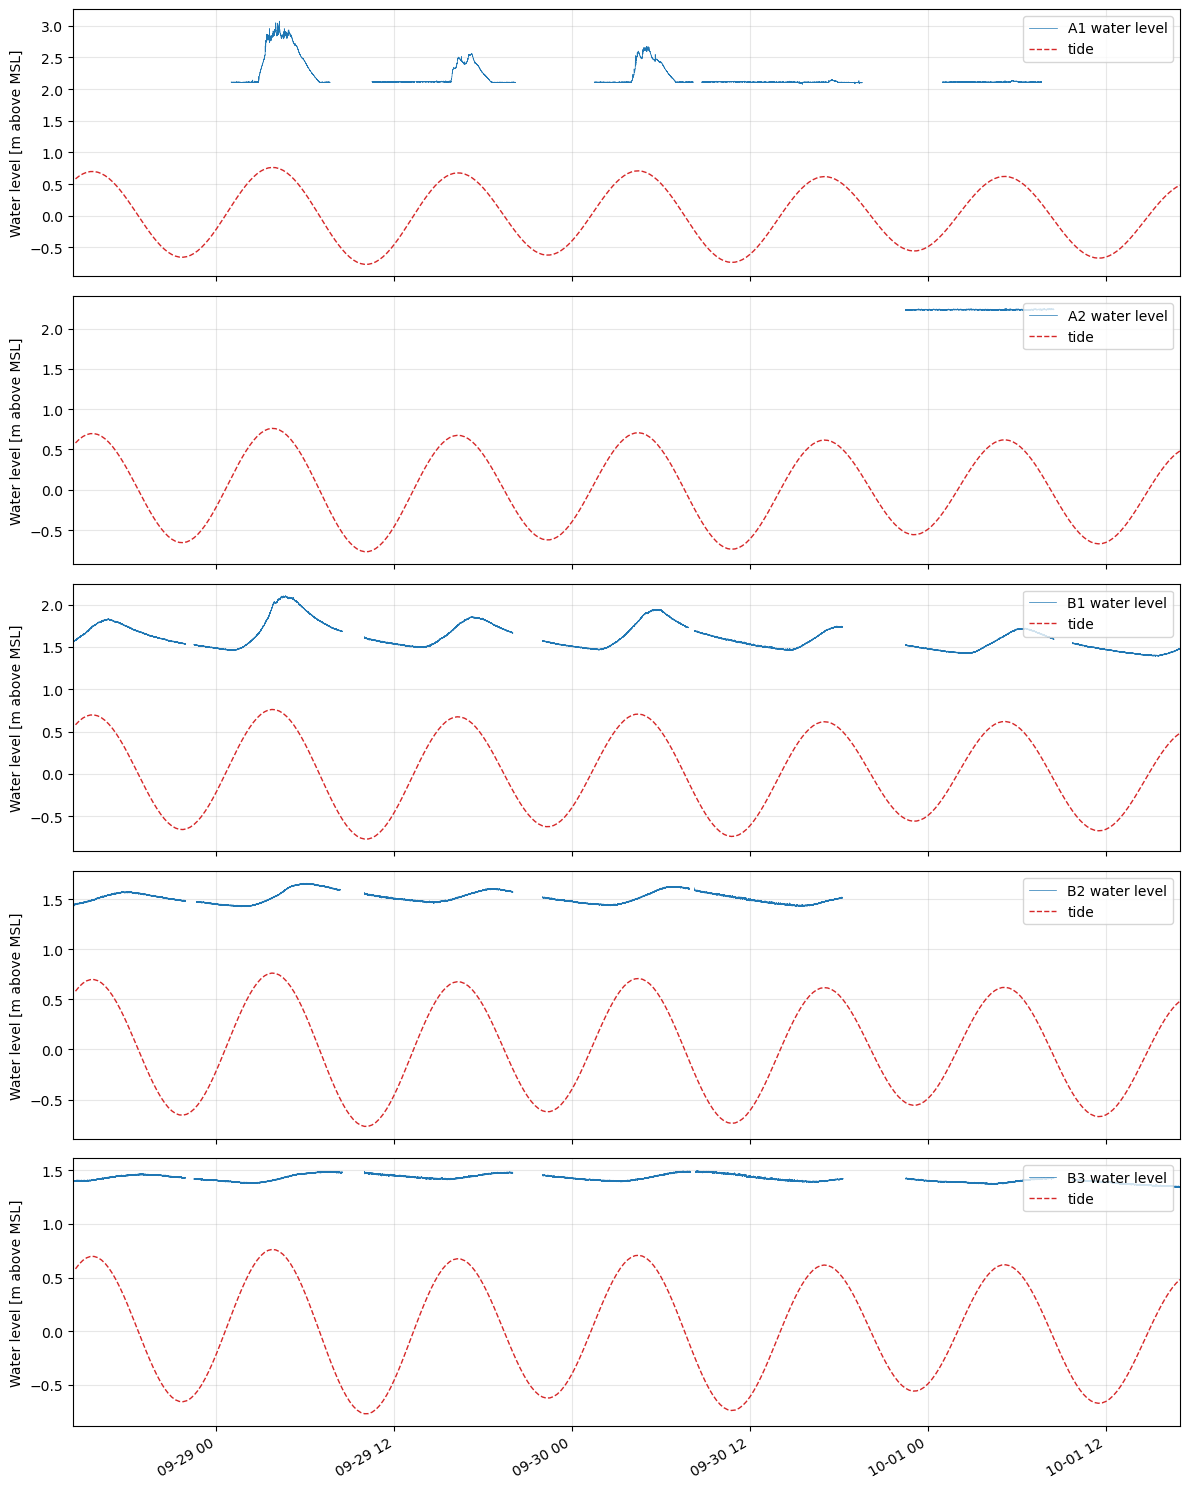

In [3]:
def read_csv(path):
    with open(path, encoding="latin-1") as f:
        lines = f.read().splitlines()
    start = next(i for i, l in enumerate(lines) if l.startswith("Date/time"))
    df = pd.read_csv(path, encoding="latin-1", skiprows=start, skipfooter=1,
                     engine="python", usecols=[0, 1], names=["time", "p"], header=0)
    df.index = pd.to_datetime(df["time"].str.strip(), format="mixed")
    return df["p"]  # pressure in cmH2O


def with_gaps(s):
    """Add a NaN at every gap so the plot shows blank space."""
    gap = s.index.to_series().diff() > pd.Timedelta(minutes=GAP_MINUTES)
    nan_rows = pd.Series(np.nan, index=s.index[gap] - pd.Timedelta(seconds=1))
    return pd.concat([s, nan_rows]).sort_index()


baro = pd.concat([read_csv(DATA_FOLDER / n) for n in BARO_FILES]).sort_index()
baro = baro[~baro.index.duplicated()]
baro = baro - BARO_OFFSET

def process_well(files, toc, offset_cm):
    """Read the Diver files of one well and return the water level (m above MSL)."""
    parts = []
    for name, (keep_from, keep_until) in files.items():
        s = read_csv(DATA_FOLDER / name).loc[keep_from:keep_until]
        if s.empty:
            print(f"  {name}: no data in the chosen window!")
            continue
        print(f"  {name}: {s.index[0]} -> {s.index[-1]}  ({len(s)} samples)")
        parts.append(s)
    diver = pd.concat(parts).sort_index()
    diver = diver[~diver.index.duplicated()]

    # barometric correction (baro is interpolated onto the 2 Hz diver times)
    baro_i = np.interp(diver.index.astype("int64"), baro.index.astype("int64"),
                       baro.values, left=np.nan, right=np.nan)
    corrected = diver - baro_i - offset_cm                   # cm of water above the Diver
    return toc - CL + corrected / 100               # water level in m above MSL


tide = pd.read_csv(DATA_FOLDER / TIDE_FILE)
tide.index = pd.to_datetime(tide["dates"], utc=True).dt.tz_localize(None)
tide.index = tide.index + pd.Timedelta(hours=TIDE_SHIFT_HOURS)
tide = tide["tide"]



results = {}
for well_name, w in WELLS.items():
    print(well_name)
    if w["z_is_top_of_casing"]:                     # A wells: drone saw the top of the casing
        toc = w["z"]
    else:                                           # B wells: drone saw the sand surface
        toc = w["z"] + w["above_sand_cm"] / 100
    print(f"  top of casing = {toc:.3f} m above MSL")
    results[well_name] = process_well(w["files"], toc,  w["offset_cm"])
    results[well_name].rename("water_level_m").to_csv(f"water_level_{well_name}.csv")


t_start = min(r.index[0] for r in results.values())
t_end = max(r.index[-1] for r in results.values())
tide_plot = tide.loc[t_start:t_end]

fig, axes = plt.subplots(len(results), 1, figsize=(12, 3 * len(results)), sharex=True)
for ax, (well_name, wl) in zip(axes, results.items()):
    wl = with_gaps(wl)
    ax.plot(wl.index, wl, color="tab:blue", lw=0.5, label=f"{well_name} water level")
    ax.plot(tide_plot.index, tide_plot, color="tab:red", lw=1, ls="--", label="tide")
    ax.set_ylabel("Water level [m above MSL]")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
axes[0].set_xlim(t_start, t_end)
fig.autofmt_xdate(); fig.tight_layout(); plt.show()

A1: at/above nesting depth (60 cm): 0.5 h
A1: shallowest water table 40.0 cm below sand, 1.2 % of the time within 60 cm
A2: at/above nesting depth (60 cm): 0.0 h
A2: shallowest water table 119.9 cm below sand, 0.0 % of the time within 60 cm
B1: at/above nesting depth (60 cm): 0.0 h
B1: shallowest water table 70.8 cm below sand, 0.0 % of the time within 60 cm
B2: at/above nesting depth (60 cm): 0.0 h
B2: shallowest water table 107.7 cm below sand, 0.0 % of the time within 60 cm
B3: at/above nesting depth (60 cm): 0.0 h
B3: shallowest water table 75.5 cm below sand, 0.0 % of the time within 60 cm


C:\Users\35389\AppData\Local\Temp\ipykernel_20432\3060864139.py:54: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.autofmt_xdate(); fig.tight_layout()


Mean water level [m above MSL]: {'B1': 1.664, 'B2': 1.532, 'B3': 1.435}


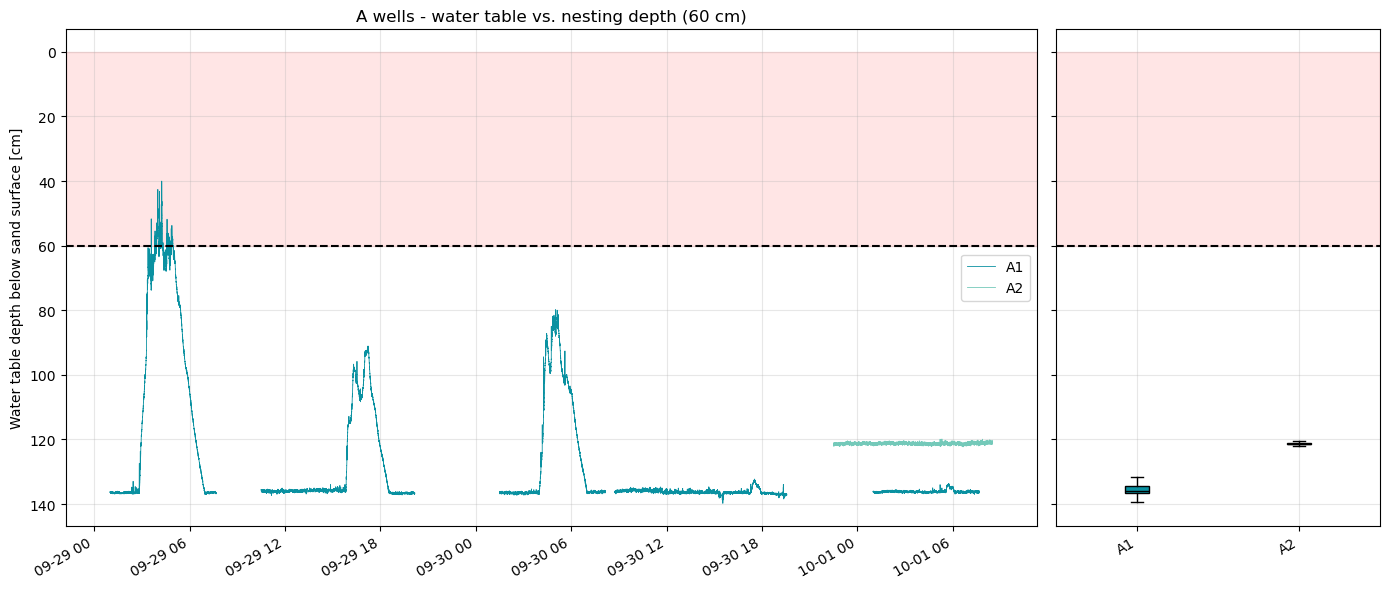

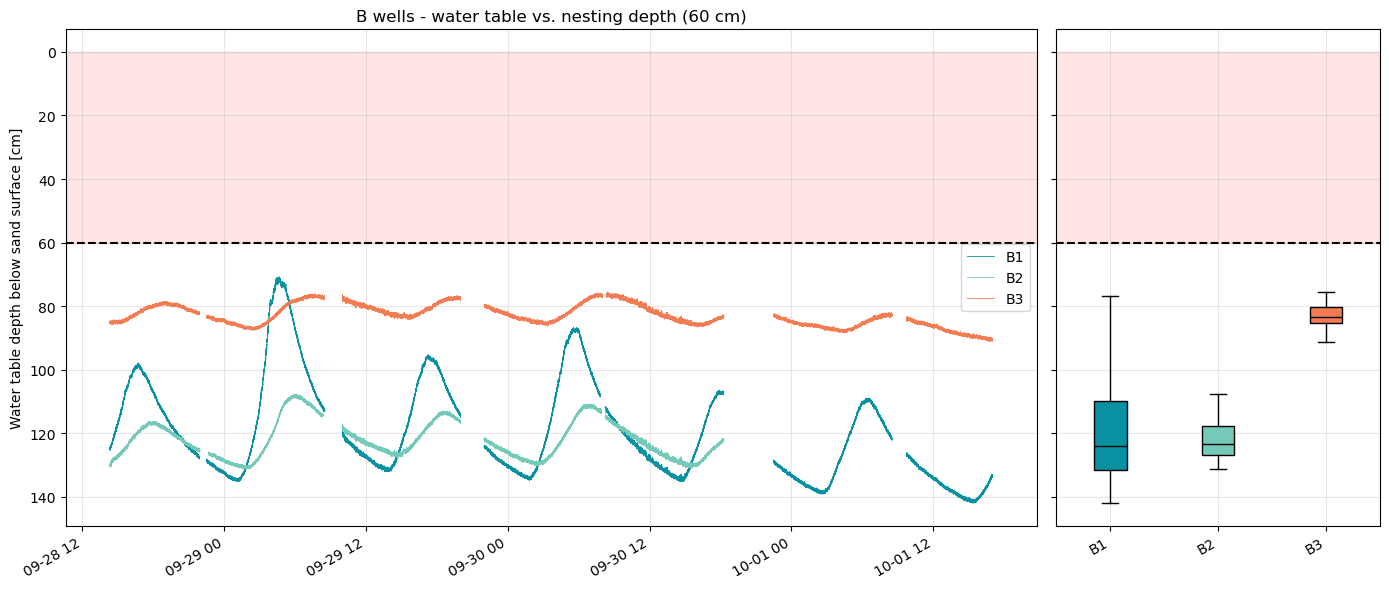

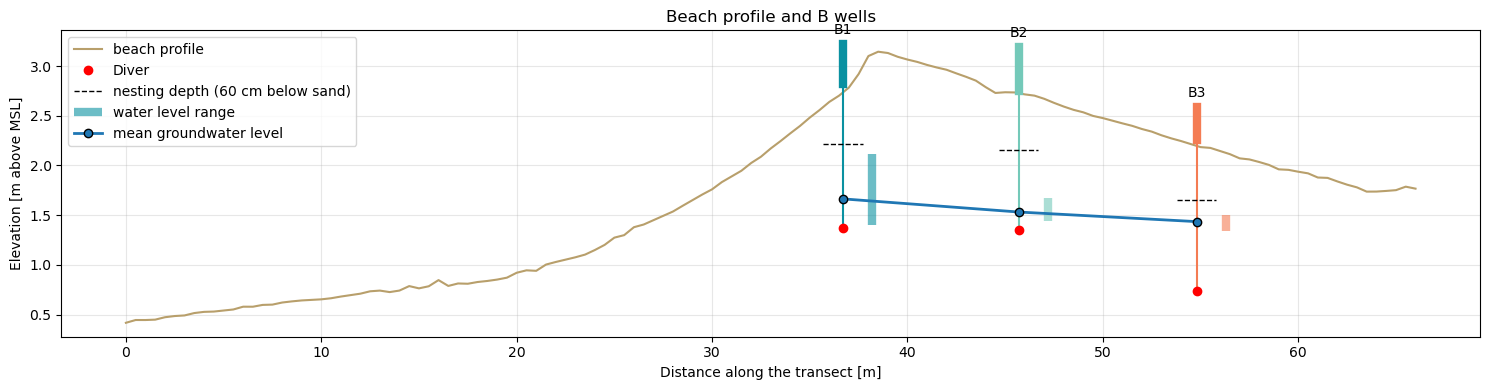

In [4]:
depth = {}
water_levels = {}
sand_levels = {}
for name, w in WELLS.items():
    # read the Diver files and keep only the chosen time windows
    parts = [read_csv(DATA_FOLDER / f).loc[start:end] for f, (start, end) in w["files"].items()]
    diver = pd.concat(parts).sort_index()
    diver = diver[~diver.index.duplicated()]

    # barometric correction -> water column above the Diver (m)
    baro_now = np.interp(diver.index.astype("int64"), baro.index.astype("int64"),
                         baro.values, left=np.nan, right=np.nan)
    water_column = (diver - baro_now) / 100

    sand_level = w["z"]                                # sand surface, m above MSL
    toc = sand_level + w["above_sand_cm"] / 100        # top of casing = sand + height measured by hand
    water_level = toc - CL + water_column              # m above MSL
    depth[name] = (sand_level - water_level) * 100    # cm below the sand surface
    water_levels[name] = water_level
    sand_levels[name] = sand_level

    d = depth[name].dropna()
    SECONDS_PER_SAMPLE = 0.5                               # Diver logs at 2 Hz
    hours_total = len(d) * SECONDS_PER_SAMPLE / 3600
    hours_surface = (d <= 0).sum() * SECONDS_PER_SAMPLE / 3600
    hours_nest = (d <= NEST_DEPTH_CM).sum() * SECONDS_PER_SAMPLE / 3600
    print(f"{name}: at/above nesting depth ({NEST_DEPTH_CM} cm): {hours_nest:.1f} h")
    print(f"{name}: shallowest water table {d.min():.1f} cm below sand, "
          f"{100 * (d <= NEST_DEPTH_CM).mean():.1f} % of the time within {NEST_DEPTH_CM} cm")

for group, names in PLOT_GROUPS.items():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True,
                                   gridspec_kw={"width_ratios": [3, 1]})

    for i, name in enumerate(names):
        d = with_gaps(depth[name])
        ax1.plot(d.index, d, lw=0.6, color=COLOURS[i], label=name)

    box = ax2.boxplot([depth[n].dropna() for n in names], patch_artist=True, showfliers=False)
    for patch, colour in zip(box["boxes"], COLOURS):
        patch.set_facecolor(colour)
    for median in box["medians"]:
        median.set_color("black")
    ax2.set_xticks(range(1, len(names) + 1), names)

    for ax in (ax1, ax2):
        ax.axhline(NEST_DEPTH_CM, color="k", ls="--")   # nesting depth
        ax.axhspan(0, NEST_DEPTH_CM, color="red", alpha=0.1)
        ax.grid(alpha=0.3)
    ax1.invert_yaxis()                                  # sand surface at the top
    ax1.set_ylabel("Water table depth below sand surface [cm]")
    ax1.set_title(f"{group} - water table vs. nesting depth ({NEST_DEPTH_CM} cm)")
    ax1.legend()
    fig.autofmt_xdate(); fig.tight_layout()


profile = pd.read_csv(DATA_FOLDER / PROFILE_FILE)
x1, y1 = WELLS["B1"]["x"], WELLS["B1"]["y"]


levels = pd.DataFrame({n: water_levels[n].resample("10min").mean() for n in ["B1", "B2", "B3"]})
levels = levels.loc[MEAN_FROM:MEAN_UNTIL].dropna()
mean_levels = levels.mean()
print("Mean water level [m above MSL]:", mean_levels.round(3).to_dict())
positions = {}

fig, ax = plt.subplots(figsize=(15, 4))
for day, colour in zip(["Wednesday"], [ "#b89f6b"]):
    ax.plot(profile["distance_m"], profile[day], color=colour, label=f"beach profile")

for i, name in enumerate(["B1", "B2", "B3"]):
    w = WELLS[name]
    pos = B1_DISTANCE_M + np.hypot(w["x"] - x1, w["y"] - y1)
    positions[name] = pos   # distance along the profile (m)
    sand = sand_levels[name]
    wl = water_levels[name]
    first = (i == 0)                                           # label the symbols only once

    toc = sand + w["above_sand_cm"] / 100

    ax.plot([pos, pos], [sand, toc], color=COLOURS[i], lw=6)                # casing above the sand
    ax.plot([pos, pos], [toc - CL, sand], color=COLOURS[i], lw=1.5)         # casing below the sand
    ax.plot(pos, toc - CL, "o", color="r", label="Diver" if first else None)
    ax.plot([pos - 1, pos + 1], [sand - NEST_DEPTH_CM / 100] * 2, "k--", lw=1,
            label=f"nesting depth ({NEST_DEPTH_CM} cm below sand)" if first else None)
    ax.vlines(pos + 1.5, wl.min(), wl.max(), color=COLOURS[i], lw=6, alpha=0.6,
              label="water level range" if first else None)
    ax.text(pos, toc + 0.1, name, ha="center")

ax.plot([positions[n] for n in ["B1", "B2", "B3"]], [mean_levels[n] for n in ["B1", "B2", "B3"]],
        "o-", color="tab:blue", lw=2, mec="k", label="mean groundwater level")
ax.set_xlabel("Distance along the transect [m]")
ax.set_ylabel("Elevation [m above MSL]")
ax.set_title("Beach profile and B wells")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()